In [38]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    log_loss,
    brier_score_loss
)
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import ExpectationMaximization
from pgmpy.readwrite import BIFWriter
from pgmpy.inference import VariableElimination
from causallearn.search.ConstraintBased.PC import pc #this seems like a good package for PC
import time
from tqdm.auto import tqdm

Credit to Ulrik Thyge Pedersen for the dataset
https://www.kaggle.com/datasets/ulrikthygepedersen/speed-dating/data
adapted from  the 2006 study of Fisman et al
https://doi.org/10.7916/D8FB585Z

In [2]:
df = pd.read_csv("speeddating.csv")
df = df.drop(columns = ['has_null','wave','match'])
X = df.drop(columns=['decision', 'decision_o'])
labels = df[['decision', 'decision_o']]

Convert ranges b'[a-b]' to the mean value

In [3]:
def convert_range(x):
    if isinstance(x, str):
        match = re.fullmatch(r"b'\[(\d+)-(\d+)\]'", x)
        if match:
            low, high = map(int, match.groups())
            return (low + high) / 2
    return x

X = X.map(convert_range)

Handling NaNs for PCA/plotting.

In [4]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns

X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])

X[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(X[cat_cols])

In [5]:
std_scaler = StandardScaler()
X_encoded = pd.get_dummies(X, drop_first=True)
X_scaled = std_scaler.fit_transform(X_encoded)

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

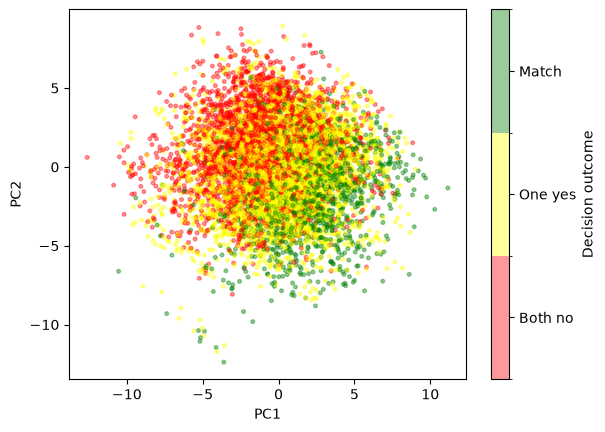

In [7]:
labels['decision'] = labels['decision'].replace({"b'1'": 1, "b'0'": 0})
labels['decision_o'] = labels['decision_o'].replace({"b'1'": 1, "b'0'": 0})

colors = labels['decision'].astype(int) + labels['decision_o'].astype(int)

cmap = ListedColormap(['red', 'yellow', 'green'])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=colors,
    cmap=cmap,
    norm=norm,
    s=7,
    alpha=0.4
)

plt.xlabel('PC1')
plt.ylabel('PC2')

cbar = plt.colorbar(ticks=[0, 1, 2])
cbar.ax.set_yticklabels(['Both no', 'One yes', 'Match'])
cbar.set_label('Decision outcome')

plt.savefig("PCA_colored.png", dpi=300)
plt.show()

Constructing the natural BN. We will condense into 5 meaningful hidden nodes.

In [8]:
demographic_vars = [
    #"wave",
    "gender",
    "age",
    "age_o",
    "d_age",
    "d_d_age",
    "race",
    "race_o",
    "samerace",
    "importance_same_race",
    "importance_same_religion",
    "d_importance_same_race",
    "d_importance_same_religion",
    "field",
]

interest_vars = [
    #"sports", "tvsports", "exercise", "dining",
    #"museums", "art", "hiking", "gaming",
    #"clubbing", "reading", "tv", "theater",
    #"movies", "concerts", "music", "shopping",
    #"yoga",

    "d_sports", "d_tvsports", "d_exercise", "d_dining",
    "d_museums", "d_art", "d_hiking", "d_gaming",
    "d_clubbing", "d_reading", "d_tv", "d_theater",
    "d_movies", "d_concerts", "d_music", "d_shopping",
    "d_yoga",

    #"interests_correlate",
    #"d_interests_correlate",
]

preference_vars = [
    #"attractive_important",
    #"sincere_important",
    #"intellicence_important",
    #"funny_important",
    #"ambition_important",
    #"shared_interests_important",

    "d_attractive_important",
    "d_sincere_important",
    "d_intellicence_important",
    "d_funny_important",
    "d_ambition_important",
    "d_shared_interests_important",

    #"importance_same_race",
    #"importance_same_religion",
    "d_importance_same_race",
    "d_importance_same_religion",
]

meta_vars = [
    "expected_happy_with_sd_people",
    #"expected_num_interested_in_me",
    #"expected_num_matches",
    "d_expected_happy_with_sd_people",
    "d_expected_num_interested_in_me",
    "d_expected_num_matches",
]

self_perception = [
    "attractive",
    "sincere",
    "intelligence",
    "funny",
    "ambition"
]

partners_perception = [
    #"pref_o_attractive",
    #"pref_o_sincere",
    #"pref_o_intelligence",
    #"pref_o_funny",
    #"pref_o_ambitious",
    #"pref_o_shared_interests",

    "attractive_o",
    "sincere_o",
    "intelligence_o",
    "funny_o",
    "ambitous_o",
    "shared_interests_o"
]

perception_of_date = [
    "like",
    "guess_prob_liked",
    "d_like",
    "d_guess_prob_liked",

    #"attractive_important",
    #"sincere_important",
    #"intellicence_important",
    #"funny_important",
    #"ambition_important",
    #"shared_interests_important",

    "attractive_partner",
    "sincere_partner",
    "intelligence_partner",
    "funny_partner",
    "ambition_partner",
    "shared_interests_partner"
]

In [9]:
latent_groups_big = {
    "demographic": demographic_vars,
    "shared_interests": interest_vars,
    "shared_preferences": preference_vars,
    "meta": meta_vars,
    "self_perception": self_perception,
    "partners_perception": partners_perception,
    "perception_of_date": perception_of_date,
}

latent_groups = {
    "demographic": demographic_vars,

    "preferences": (
        interest_vars
        + preference_vars
    ),

    "perceptions": (
        self_perception
        + partners_perception
        + perception_of_date
        #+ meta_vars
    )
}

latent_nodes = list(latent_groups.keys())

observed_nodes = [
    v for features in latent_groups.values()
    for v in features
]

edges = []

for latent, features in latent_groups.items():
    for feature in features:
        edges.append((latent, feature))

for latent in latent_groups:
    edges.append((latent, "decision"))
    edges.append((latent, "decision_o"))

model = DiscreteBayesianNetwork(
    edges,
    latents=set(latent_groups.keys())
)

"""
pos = {}

for i, node in enumerate(observed_nodes):
    pos[node] = (0, -i)

for i, node in enumerate(latent_nodes):
    pos[node] = (3, -i * len(observed_nodes) / len(latent_nodes))

plt.figure(figsize=(16, 14))

nx.draw_networkx_nodes(
    model, pos,
    nodelist=observed_nodes,
    node_color="lightblue",
    node_size=300
)

nx.draw_networkx_nodes(
    model, pos,
    nodelist=latent_nodes,
    node_color="lightgreen",
    node_size=1800
)

nx.draw_networkx_edges(
    model, pos,
    arrows=True,
    alpha=0.25
)

nx.draw_networkx_labels(model, pos, font_size=7)

plt.axis("off")
plt.savefig("BN_structure.png", dpi=300, bbox_inches="tight")
plt.show()
"""

'\npos = {}\n\nfor i, node in enumerate(observed_nodes):\n    pos[node] = (0, -i)\n\nfor i, node in enumerate(latent_nodes):\n    pos[node] = (3, -i * len(observed_nodes) / len(latent_nodes))\n\nplt.figure(figsize=(16, 14))\n\nnx.draw_networkx_nodes(\n    model, pos,\n    nodelist=observed_nodes,\n    node_color="lightblue",\n    node_size=300\n)\n\nnx.draw_networkx_nodes(\n    model, pos,\n    nodelist=latent_nodes,\n    node_color="lightgreen",\n    node_size=1800\n)\n\nnx.draw_networkx_edges(\n    model, pos,\n    arrows=True,\n    alpha=0.25\n)\n\nnx.draw_networkx_labels(model, pos, font_size=7)\n\nplt.axis("off")\nplt.savefig("BN_structure.png", dpi=300, bbox_inches="tight")\nplt.show()\n'

In [10]:
df = pd.read_csv("speeddating.csv")
df = df.drop(columns = ['has_null','wave'])

observed_cols = list(dict.fromkeys(
    [v for features in latent_groups.values() for v in features]
    + ["decision", "decision_o"]
))

data = df[observed_cols].copy()
data = data.dropna(subset=["decision", "decision_o"]) #don't keep any data that doesn't have both decisions

In [11]:
for col in data.columns: #discretize numerical values (fewer buckets)
    if pd.api.types.is_numeric_dtype(data[col]):
        if data[col].nunique() > 10:
            data[col] = pd.qcut(
                data[col], q=3, labels=False, duplicates="drop"
            )

category_maps = {}

missing_label = "<MISSING>"

for col in data.columns:
    categorical = pd.Categorical(data[col])

    #handle missing entries
    categorical = categorical.add_categories([missing_label])
    categorical = categorical.fillna(missing_label)

    data[col] = categorical.codes

    #save the reverse mapping.
    category_maps[col] = {
        i: category
        for i, category in enumerate(categorical.categories)
    }

data = data.astype(int)


In [12]:
df = pd.read_csv("speeddating.csv")
df = df.drop(columns=["has_null", "wave"])

observed_cols = list(dict.fromkeys(
    [v for features in latent_groups.values() for v in features]
    + ["decision", "decision_o"]
))

missing_cols = set(observed_cols) - set(df.columns)
assert not missing_cols, f"Missing columns: {missing_cols}"

data = df[observed_cols].copy()

# Require both decisions.
data = data.dropna(subset=["decision", "decision_o"]).copy()

# Split BEFORE preprocessing.
train_raw, test_raw = train_test_split(
    data,
    test_size=0.15,
    random_state=42
)

train_data = train_raw.copy()
test_data = test_raw.copy()

# Store preprocessing information for reuse.
category_maps = {}
bin_edges = {}
missing_label = "<MISSING>"

# Discretize numerical variables using TRAINING data only.
for col in train_data.columns:
    if pd.api.types.is_numeric_dtype(train_data[col]):
        if train_data[col].nunique() > 10:
            _, edges = pd.qcut(
                train_data[col],
                q=3,
                retbins=True,
                duplicates="drop"
            )

            # Expand endpoints so test values outside the training
            # range are still assigned to a bin.
            edges[0] = -np.inf
            edges[-1] = np.inf

            bin_edges[col] = edges

            train_data[col] = pd.cut(
                train_data[col],
                bins=edges,
                labels=False,
                include_lowest=True
            )

            test_data[col] = pd.cut(
                test_data[col],
                bins=edges,
                labels=False,
                include_lowest=True
            )

# Encode categories using TRAINING categories only.
for col in train_data.columns:
    train_raw_col = train_data[col].astype(object)
    test_raw_col = test_data[col].astype(object)

    categories = list(pd.unique(train_raw_col.dropna()))

    if missing_label in categories:
        raise ValueError(f"{missing_label} already occurs in {col}")

    categories.append(missing_label)

    # Add a fallback category for unseen test values.
    unknown_label = "<UNKNOWN>"
    categories.append(unknown_label)

    train_raw_col = train_raw_col.where(
        train_raw_col.notna(), missing_label
    )
    test_raw_col = test_raw_col.where(
        test_raw_col.notna(), missing_label
    )

    test_raw_col = test_raw_col.where(
        test_raw_col.isin(categories),
        unknown_label
    )

    train_data[col] = pd.Categorical(
        train_raw_col,
        categories=categories
    ).codes.astype(int)

    test_data[col] = pd.Categorical(
        test_raw_col,
        categories=categories
    ).codes.astype(int)

    category_maps[col] = {
        i: category
        for i, category in enumerate(categories)
    }

# Explicitly specify all possible states.
state_names = {
    col: list(range(len(category_maps[col])))
    for col in train_data.columns
}

# Sanity checks.
assert not train_data.isna().any().any()
assert not test_data.isna().any().any()

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)
print(f"Training fraction: {len(train_data) / len(data):.1%}")
print(f"Testing fraction: {len(test_data) / len(data):.1%}")

Training data: (7121, 59)
Testing data: (1257, 59)
Training fraction: 85.0%
Testing fraction: 15.0%


In [26]:
latent_card = {
    node: 3
    for node in latent_nodes
}

# Initialize and run EM.
em = ExpectationMaximization(
    model=model,
    data=train_data,
    state_names=state_names
)

start = time.time()

iterations = 50

cpds = em.get_parameters(
    latent_card=latent_card,
    max_iter=iterations,
    atol=1e-5,
    seed=42,
    n_jobs=4,
    batch_size=500,
    show_progress=True
)

print(iterations, "iterations took:", round(time.time() - start, 2), "seconds")

# Attach learned CPDs to the model.
model.add_cpds(*cpds)

# Verify the resulting Bayesian network.
assert model.check_model()

print("EM finished successfully!")

/var/folders/mr/fcr4_q2x7r92n0ld8cqw51g00000gq/T/ipykernel_90338/3563080939.py:7: FutureWarning: `pgmpy.estimators.ExpectationMaximization` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteEM` instead.
  em = ExpectationMaximization(
  0%|          | 0/50 [00:00<?, ?it/s]/opt/miniconda3/envs/sklearn-env/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (
/opt/miniconda3/envs/sklearn-env/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (
/opt/miniconda3/envs/sklearn-env/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be rem

50 iterations took: 1461.18 seconds
EM finished successfully!


In [27]:
writer = BIFWriter(model)
filename = "speed_dating_model_" + str(iterations) + ".bif"
writer.write_bif(filename)

/var/folders/mr/fcr4_q2x7r92n0ld8cqw51g00000gq/T/ipykernel_90338/1680029679.py:3: FutureWarning: `BIFWriter.write_bif` is deprecated and will be removed in v1.3.0. Please use `BIFWriter.write` instead.
  writer.write_bif(filename)


In [29]:
feature_nodes = [
    col for col in observed_nodes
    if col not in ["decision", "decision_o"]
]

infer = VariableElimination(model)

print("Decision mapping:", category_maps["decision"])
print("Decision_o mapping:", category_maps["decision_o"])


Decision mapping: {0: "b'1'", 1: "b'0'", 2: '<MISSING>', 3: '<UNKNOWN>'}
Decision_o mapping: {0: "b'1'", 1: "b'0'", 2: '<MISSING>', 3: '<UNKNOWN>'}


In [40]:
positive_state = 0

def predict_probabilities(row):
    """
    Predict P(decision=1), P(decision_o=1), and P(match=1)
    using only the observed features.
    """

    evidence = {
        col: int(row[col])
        for col in feature_nodes
    }

    # Posterior distribution over all latent variables.
    posterior = infer.query(
        variables=latent_nodes,
        evidence=evidence,
        show_progress=False
    )

    p_decision = 0.0
    p_decision_o = 0.0
    p_match = 0.0

    # Enumerate all joint latent configurations.
    import itertools

    latent_states = [
        range(latent_card[node])
        for node in latent_nodes
    ]

    for assignment in itertools.product(*latent_states):
        z = dict(zip(latent_nodes, assignment))

        # Posterior probability of this latent configuration.
        p_z = posterior.get_value(**z)

        # Conditional decision probabilities given Z.
        p1 = model.get_cpds("decision").get_value(
            decision=positive_state,
            **z
        )

        p2 = model.get_cpds("decision_o").get_value(
            decision_o=positive_state,
            **z
        )

        p_decision += p_z * p1
        p_decision_o += p_z * p2
        p_match += p_z * p1 * p2

    return p_decision, p_decision_o, p_match

In [41]:
predictions = []

for _, row in tqdm(test_data.iterrows(), total=len(test_data)):
    predictions.append(predict_probabilities(row))

predictions = np.array(predictions)

results = pd.DataFrame({
    "p_decision": predictions[:, 0],
    "p_decision_o": predictions[:, 1],
    "p_match": predictions[:, 2],
}, index=test_data.index)

print(results.head())

100%|██████████| 1257/1257 [00:03<00:00, 390.97it/s]

      p_decision  p_decision_o   p_match
4730    0.158930      0.408799  0.064970
8168    0.278082      0.169997  0.047279
2333    0.622796      0.483498  0.301102
5426    0.247945      0.309306  0.076691
5407    0.712629      0.479154  0.341449


In [42]:
def evaluate_predictions(y_true, probabilities):
    predicted = (probabilities >= 0.5).astype(int)

    return {
        "AUC": roc_auc_score(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predicted),
        "Log Loss": log_loss(y_true, probabilities),
        "Brier Score": brier_score_loss(y_true, probabilities)
    }

positive_decision = 0
positive_decision_o = 0

y_decision = (
    test_data["decision"] == positive_decision
).astype(int)

y_decision_o = (
    test_data["decision_o"] == positive_decision_o
).astype(int)

y_match = (y_decision & y_decision_o).astype(int)

metrics = pd.DataFrame({
    "decision": evaluate_predictions(y_decision, results["p_decision"]),
    "decision_o": evaluate_predictions(y_decision_o, results["p_decision_o"]),
    "match": evaluate_predictions(y_match, results["p_match"])
}).T

print(metrics)

                 AUC  Accuracy  Log Loss  Brier Score
decision    0.762061  0.703262  0.582709     0.198070
decision_o  0.578440  0.591090  0.671827     0.239006
match       0.722691  0.821798  0.421740     0.133622


TODO: Run MLE on our BN to construct CPTs (use only ~85% of the data, reserve 15% for testing)
- If we decide to introduce hidden nodes, we will instead need to use EM to construct the CPTs.

TODO: Use the PC algorithm to construct a a BN, use MLE again to construct CPTs

TODO: Use PC algorithm again, this given only survey responses. How does it compare?

TODO: Is there any nice data visualization we can do?